# ECON 524 — Lab: Debiased Machine Learning II
## The Riesz representer and automatic DML

**Friday, November 13, 2026 · 50 minutes** · Lab instructor: Joel Reyes Mora

Covers **Lecture 4, Section 3 (slides 26–50)**. Builds on last week's lab (orthogonality + cross-fitting).

---

**Where we are.** Last Friday every orthogonal score came from a *model*: we partialled $Z$ out of $Y = D\theta_0 + g_0(Z) + U$. But the targets we actually care about (ATE, LATE, group-time ATT) are defined **without** a parametric model; they are averages of a regression function (slide 29). The question of this lab:

> *Given a target $\theta_0 = E[m(X,\gamma_0)]$ with $\gamma_0(D,Z)=E[Y\mid D,Z]$ learned by ML, how do we build an orthogonal score, and how do we estimate the extra nuisance it needs, without knowing its formula?*

The answer has two pieces: the **Riesz representer** $\alpha_0$ (what to add) and **Riesz regression** (how to learn $\alpha_0$ automatically).

| Block | Time | Slides |
|---|---|---|
| 0. Setup | 2 min | — |
| 1. The Riesz representer, by hand and by simulation | 11 min | 27–32 |
| 2. Why $\alpha_0$ debiases: orthogonality and double robustness | 11 min | 33–36 |
| 3. Riesz regression: learning $\alpha_0$ without its formula | 14 min | 37–41 |
| 4. Automatic DML: ATE under weak overlap, then LATE | 10 min | 42–48 |
| 5. Wrap-up (and a DiD preview for Assignment 4) | 2 min | 49–50 |

All data are simulated. The notebook runs in about 2 minutes; the neural-network cells need `torch` (as in the deep-learning lab).

## 0. Setup

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
warnings.filterwarnings("ignore")

BLUE, ORANGE, AQUA, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    HAS_TORCH = True
    torch.manual_seed(0)
except ImportError:
    HAS_TORCH = False
    print("torch not found: the RieszNet cells will be skipped (pip install torch).")

## 1. The Riesz representer, by hand and by simulation (slides 27–32) · 11 min

**Parameters as functionals (slides 28–29).** Each target is $\theta_0 = E[m(X,\gamma_0)]$ for a known map $m$:

| Target | $m(X,\gamma)$ | linear in $\gamma$? |
|---|---|---|
| ATE | $\gamma(1,Z)-\gamma(0,Z)$ | yes |
| ATT | $D\{\gamma(1,Z)-\gamma(0,Z)\}/P(D=1)$ | yes |
| LATE | ratio of two ATE-type functionals in the instrument $W$ | each piece is |
| GT-ATT (DiD) | ATT-type functional of $E[\Delta Y\mid C_{gt}, Z]$ | yes |

**Riesz representation theorem (slide 31).** On $H = L^2(D,Z)$ with $\langle\gamma,\eta\rangle = E[\gamma(D,Z)\eta(D,Z)]$, a linear functional $\phi(\gamma)=E[m(X,\gamma)]$ is continuous iff there is a unique $\alpha_0\in H$ with
$$E[m(X,\gamma)] = E[\alpha_0(D,Z)\,\gamma(D,Z)]\qquad\text{for all }\gamma .$$

### 1a. A Hilbert space you can write down
Let $Z$ take 4 values and $D\in\{0,1\}$. A function $\gamma(d,z)$ is then just a vector in $\mathbb R^8$, and the inner product is a **weighted dot product** with weights $w(d,z) = P(D=d, Z=z)$:
$$\langle\gamma,\eta\rangle = \sum_{d,z} w(d,z)\,\gamma(d,z)\eta(d,z).$$
Any linear functional is $\phi(\gamma) = c^\top\gamma$ for some vector $c$. Riesz says: find $\alpha_0$ with $\sum w\,\alpha_0\,\gamma = c^\top\gamma$ for all $\gamma$, so **$\alpha_0 = c/w$ elementwise**. That is the whole theorem in finite dimensions.

For the ATE, $c(1,z) = P(Z=z)$ and $c(0,z) = -P(Z=z)$, so $\alpha_0(1,z) = \frac{P(z)}{P(z)\varrho_0(z)} = \frac{1}{\varrho_0(z)}$ and $\alpha_0(0,z) = -\frac{1}{1-\varrho_0(z)}$: the **Horvitz–Thompson** weight of slide 32 falls out of linear algebra.

In [2]:
pz  = np.array([0.1, 0.2, 0.3, 0.4])          # P(Z = z)
rho = np.array([0.2, 0.5, 0.7, 0.9])          # propensity  P(D = 1 | Z = z)
w = np.concatenate([pz * (1 - rho), pz * rho])  # cell weights: first the four (d=0,z) cells, then (d=1,z)

def riesz_by_hand(c):            # alpha0 = c / w
    return c / w

c_ate = np.concatenate([-pz, pz])                       # ATE: sum_z P(z)[gamma(1,z) - gamma(0,z)]
pD = pz @ rho
c_att = np.concatenate([-pz * rho, pz * rho]) / pD      # ATT: E[D{gamma(1,Z)-gamma(0,Z)}]/P(D=1)

out = pd.DataFrame({"d": [0]*4 + [1]*4, "z": list(range(1, 5)) * 2,
                    "alpha_ATE (by hand)": riesz_by_hand(c_ate),
                    "Horvitz-Thompson": np.concatenate([-1 / (1 - rho), 1 / rho]),
                    "alpha_ATT (by hand)": riesz_by_hand(c_att),
                    "-rho/((1-rho)P(D=1)) or 1/P(D=1)": np.concatenate([-rho / ((1 - rho) * pD), np.full(4, 1 / pD)])})
display(out.round(3))

rng = np.random.default_rng(0)
for _ in range(3):
    g = rng.standard_normal(8)                           # an arbitrary "regression function"
    print(f"phi_ATE(gamma) = {c_ate @ g:+.4f}   <alpha_ATE, gamma> = {np.sum(w * riesz_by_hand(c_ate) * g):+.4f}")

,d,z,alpha_ATE (by hand),Horvitz-Thompson,alpha_ATT (by hand),-rho/((1-rho)P(D=1)) or 1/P(D=1)
0,0,1,-1.250,-1.250,-0.362,-0.362
1,0,2,-2.000,-2.000,-1.449,-1.449
2,0,3,-3.333,-3.333,-3.382,-3.382
3,0,4,-10.000,-10.000,-13.043,-13.043
4,1,1,5.000,5.000,1.449,1.449
5,1,2,2.000,2.000,1.449,1.449
6,1,3,1.429,1.429,1.449,1.449
7,1,4,1.111,1.111,1.449,1.449


phi_ATE(gamma) = +0.5685   <alpha_ATE, gamma> = +0.5685
phi_ATE(gamma) = -0.4490   <alpha_ATE, gamma> = -0.4490
phi_ATE(gamma) = -0.2213   <alpha_ATE, gamma> = -0.2213


**Read the table.** The same one-line recipe produced two different representers. The ATT representer puts weight $1/P(D=1)$ on treated cells and the **odds** $-\varrho_0/(1-\varrho_0)$ (scaled) on control cells. Keep this shape in mind: slide 50's representer for the DiD group-time ATT, $-P(G=g\mid Z)C_{gt}/\{\eta_{g,0}P(C_{gt}=1\mid Z)\}$, is exactly this odds form with the comparison group in place of $D=0$.

### 1b. Continuous $Z$: check the representation by simulation
With a continuous, 20-dimensional $Z$ we can no longer list cells, but the identity $E[\gamma(1,Z)-\gamma(0,Z)] = E[\alpha_0\gamma]$ must still hold **for any** $\gamma$, even silly ones nobody would fit. Our running DGP (used for the rest of the lab):
$$\varrho_0(Z) = \operatorname{expit}\{\kappa(Z_1 + 0.5Z_2 - 0.5Z_3^2 + 0.5)\},\quad Y = \mu(Z) + D\,\tau(Z) + \varepsilon,$$
$\mu(Z) = Z_1 + \sin(2Z_2) + 0.5Z_3^2 + 0.25Z_4$, $\tau(Z) = 1 + 0.5Z_1$ (so the **ATE is 1**), $p=20$. The parameter $\kappa$ controls **overlap**: larger $\kappa$ pushes propensities toward 0 and 1.

In [3]:
def dgp_ate(n, p=20, kappa=1.0, seed=0):
    r = np.random.default_rng(seed)
    Z = r.standard_normal((n, p))
    ps = expit(kappa * (Z[:, 0] + 0.5 * Z[:, 1] - 0.5 * Z[:, 2] ** 2 + 0.5))
    D = (r.uniform(size=n) < ps).astype(float)
    Y = Z[:, 0] + np.sin(2 * Z[:, 1]) + 0.5 * Z[:, 2] ** 2 + 0.25 * Z[:, 3] + D * (1 + 0.5 * Z[:, 0]) + r.standard_normal(n)
    return Y, D, Z, ps

def gamma0(d, Z):                       # true E[Y | D=d, Z]
    return Z[:, 0] + np.sin(2 * Z[:, 1]) + 0.5 * Z[:, 2] ** 2 + 0.25 * Z[:, 3] + d * (1 + 0.5 * Z[:, 0])

def ht(D, ps):                          # Horvitz-Thompson Riesz representer for the ATE (slide 32)
    return D / ps - (1 - D) / (1 - ps)

Y, D, Z, ps = dgp_ate(1_000_000, kappa=0.5, seed=1)
a0 = ht(D, ps)
one, zero = np.ones_like(D), np.zeros_like(D)
weird = {"sin(Z1) + D*Z2^2": lambda d, z: np.sin(z[:, 0]) + d * z[:, 1] ** 2,
         "Z1*Z3 + 3*D*1{Z1>0}": lambda d, z: z[:, 0] * z[:, 2] + 3 * d * (z[:, 0] > 0),
         "true gamma0": gamma0}
for name, gam in weird.items():
    lhs = np.mean(gam(one, Z) - gam(zero, Z)); rhs = np.mean(a0 * gam(D, Z))
    print(f"{name:<22}  E[m(X,gamma)] = {lhs:.3f}   E[alpha0*gamma] = {rhs:.3f}")

sin(Z1) + D*Z2^2        E[m(X,gamma)] = 1.001   E[alpha0*gamma] = 1.004
Z1*Z3 + 3*D*1{Z1>0}     E[m(X,gamma)] = 1.504   E[alpha0*gamma] = 1.500


true gamma0             E[m(X,gamma)] = 1.001   E[alpha0*gamma] = 0.999


Both sides agree up to simulation noise for arbitrary $\gamma$. The last line is the familiar IPW identity $\theta_0 = E[\alpha_0\gamma_0] = E[\alpha_0 Y]$. **The Riesz representer is the weighting function that turns "evaluate $\gamma$ at counterfactual treatment values" into "average $\gamma$ at the observed data".**

## 2. Why $\alpha_0$ debiases (slides 33–36) · 11 min

**The orthogonal moment (slide 33).** If $\gamma\mapsto E[m(X,\gamma)]$ is linear and continuous and $\gamma_0=E[Y|D,Z]$,
$$\theta_0 = E\big[\,m(X,\gamma_0) + \alpha_0(D,Z)\{Y-\gamma_0(D,Z)\}\,\big],$$
because the added term has mean zero by the law of iterated expectations.

**Orthogonality in one line each (slide 34).** Perturb $\gamma_0\to\gamma_0 + t\delta$:
$$\tfrac{d}{dt}E[m(X,\gamma_0+t\delta) + \alpha_0(Y-\gamma_0-t\delta)] = E[m(X,\delta)] - E[\alpha_0\delta] = 0\quad\text{(Riesz!)}$$
Perturb $\alpha_0\to\alpha_0+t\delta$: $\ \tfrac{d}{dt}(\cdot) = E[\delta\,(Y-\gamma_0)] = 0$ (LIE).

**The exchange rate.** For the plug-in estimator $E[m(X,\hat\gamma)]$, the bias is exactly $E[m(X,\hat\gamma-\gamma_0)] = E[\alpha_0(\hat\gamma-\gamma_0)]$. So $\alpha_0$ is the *exchange rate* that converts errors in $\gamma$ into errors in $\theta$, and the correction term $E[\alpha_0(Y-\hat\gamma)] = -E[\alpha_0(\hat\gamma-\gamma_0)]$ cancels them.

**Double robustness (slide 35).** For any pair $(\gamma,\alpha)$:
$$E[m(X,\gamma)+\alpha(Y-\gamma)] - \theta_0 = -E\big[(\alpha-\alpha_0)(\gamma-\gamma_0)\big].$$
(Proof: add and subtract, use $E[m(X,\gamma-\gamma_0)] = E[\alpha_0(\gamma-\gamma_0)]$ and $E[\alpha(Y-\gamma_0)]=0$.) The error is a **product**, which is the general version of last week's "slope 2".

### 2a. See it: perturb the nuisances along a path

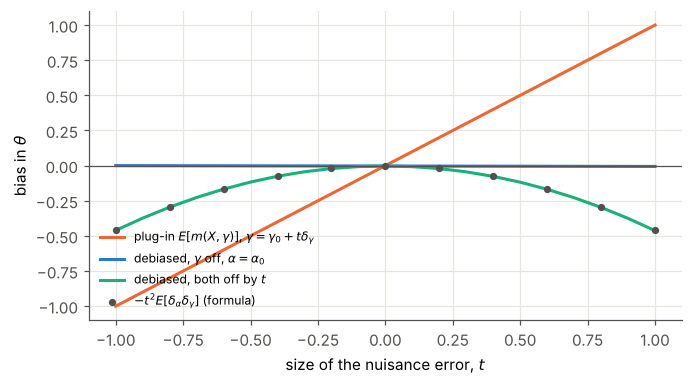

In [4]:
Yb, Db, Zb, psb = dgp_ate(400_000, kappa=0.5, seed=2)
a0b = ht(Db, psb); one, zero = np.ones_like(Db), np.zeros_like(Db)
theta0 = np.mean(1 + 0.5 * Zb[:, 0])                      # finite-sample truth (~1)
delta_g = lambda d, z: 0.5 + d * (1 + z[:, 0]) + z[:, 1]  # an error direction for gamma (E[m(X,delta_g)] = 1)
delta_a = lambda d, z: (2 * d - 1) * z[:, 1] + 0.3        # an error direction for alpha

ts = np.linspace(-1, 1, 21)
rows = []
for t in ts:
    gt = lambda d, z: gamma0(d, z) + t * delta_g(d, z)
    at = a0b + t * delta_a(Db, Zb)
    rows.append(dict(t=t,
        plug_in=np.mean(gt(one, Zb) - gt(zero, Zb)) - theta0,
        debiased_gamma_off=np.mean(gt(one, Zb) - gt(zero, Zb) + a0b * (Yb - gt(Db, Zb))) - theta0,
        debiased_both_off=np.mean(gt(one, Zb) - gt(zero, Zb) + at * (Yb - gt(Db, Zb))) - theta0,
        product_formula=-t**2 * np.mean(delta_a(Db, Zb) * delta_g(Db, Zb))))
path = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(path.t, path.plug_in, color=ORANGE, label=r"plug-in $E[m(X,\gamma)]$, $\gamma = \gamma_0 + t\delta_\gamma$")
ax.plot(path.t, path.debiased_gamma_off, color=BLUE, label=r"debiased, $\gamma$ off, $\alpha = \alpha_0$")
ax.plot(path.t, path.debiased_both_off, color=AQUA, label=r"debiased, both off by $t$")
ax.scatter(path.t[::2], path.product_formula[::2], color=INK2, s=14, zorder=3, label=r"$-t^2E[\delta_\alpha\delta_\gamma]$ (formula)")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlabel("size of the nuisance error, $t$"); ax.set_ylabel(r"bias in $\theta$")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

**Read the plot.** The plug-in moves one-for-one with the error (its slope is $E[m(X,\delta_\gamma)]=1$). With $\alpha_0$ in hand, the debiased moment does not move **at all** when only $\gamma$ is wrong; for linear functionals this holds exactly, not just at first order. When both are wrong, the bias is the product $-t^2E[\delta_\alpha\delta_\gamma]$ (dots).

### 2b. Double robustness in a Monte Carlo (slide 36)
Use parametric fits so that "correct" and "wrong" are unambiguous:
* $\gamma$ **correct**: OLS (by treatment arm) on the true terms $\{1, Z_1, \sin 2Z_2, Z_3^2, Z_4\}$; $\gamma$ **wrong**: OLS on $Z_1,\dots,Z_4$ linearly.
* $\alpha$ **correct**: HT with a logit on the true index terms $\{Z_1,Z_2,Z_3^2\}$; $\alpha$ **wrong**: logit on $\{Z_1,Z_2,Z_3\}$.

In [5]:
def fit_gamma(Y, D, Z, correct):
    B = np.column_stack([np.ones(len(Z)), Z[:, 0], np.sin(2 * Z[:, 1]), Z[:, 2] ** 2, Z[:, 3]]) if correct \
        else np.column_stack([np.ones(len(Z)), Z[:, :4]])
    b1 = np.linalg.lstsq(B[D == 1], Y[D == 1], rcond=None)[0]
    b0 = np.linalg.lstsq(B[D == 0], Y[D == 0], rcond=None)[0]
    return B @ b1, B @ b0

def fit_alpha(D, Z, correct):
    B = np.column_stack([Z[:, 0], Z[:, 1], Z[:, 2] ** 2]) if correct else Z[:, :3]
    p = LogisticRegression(C=1e6, max_iter=2000).fit(B, D).predict_proba(B)[:, 1]
    return ht(D, p)

R_dr = 100
t0 = time.time()
rows = []
for g_ok in [True, False]:
    for a_ok in [True, False]:
        est = []
        for r in range(R_dr):
            Y, D, Z, _ = dgp_ate(5000, kappa=0.5, seed=r)
            g1, g0_ = fit_gamma(Y, D, Z, g_ok); a = fit_alpha(D, Z, a_ok)
            est.append([np.mean(g1 - g0_), np.mean(a * Y), np.mean(g1 - g0_ + a * (Y - np.where(D == 1, g1, g0_)))])
        e = np.array(est) - 1
        rows.append({"gamma": "correct" if g_ok else "WRONG", "alpha": "correct" if a_ok else "WRONG",
                     "bias plug-in E[m(X,g)]": e[:, 0].mean(), "bias IPW E[aY]": e[:, 1].mean(),
                     "bias debiased (DR)": e[:, 2].mean(), "sd debiased": e[:, 2].std()})
print(f"{R_dr} reps x 4 cells in {time.time()-t0:.1f}s (n = 5000, truth = 1)")
pd.DataFrame(rows).set_index(["gamma", "alpha"]).round(3)

100 reps x 4 cells in 2.0s (n = 5000, truth = 1)


bias plug-in E[m(X,g)]  bias IPW E[aY]  bias debiased (DR)  \
gamma   alpha                                                                 
correct correct                   0.003           0.002               0.003   
        WRONG                     0.003          -0.221               0.003   
WRONG   correct                  -0.219           0.002              -0.001   
        WRONG                    -0.219          -0.221              -0.222   

                 sd debiased  
gamma   alpha                 
correct correct        0.028  
        WRONG          0.028  
WRONG   correct        0.037  
        WRONG          0.042

**Read the table.** The plug-in is only as good as $\hat\gamma$; IPW is only as good as $\hat\alpha$. The debiased estimator is fine if **either** is right and fails only when **both** are wrong, exactly as the product formula predicts. Slide 36's practical point: even with flexible ML for both nuisances (neither exactly "right"), the product structure is what makes the remaining bias small (Rothe & Firpo, 2019).

## 3. Riesz regression: learning $\alpha_0$ without its formula (slides 37–41) · 14 min

### 3a. Why not just plug in $1/\hat\varrho$?
Slide 37 lists two problems. (i) $\alpha_0$ involves $1/\varrho_0$, and inverting an estimate amplifies its error by $1/\varrho^2$ exactly where $\varrho_0$ is small. (ii) For many targets, $\alpha_0$ has **no** convenient closed form. Look at how extreme the *true* representer already is when overlap weakens:

In [6]:
rows = []
for kappa in [0.5, 1.0, 1.5]:
    _, D, _, ps = dgp_ate(200_000, kappa=kappa, seed=3)
    a = np.abs(ht(D, ps))
    rows.append({"kappa": kappa, "share ps<0.05 or >0.95": np.mean((ps < .05) | (ps > .95)),
                 "median |alpha0|": np.median(a), "99th pct |alpha0|": np.quantile(a, .99), "max |alpha0|": a.max()})
pd.DataFrame(rows).set_index("kappa").round(3)

,share ps<0.05 or >0.95,median |alpha0|,99th pct |alpha0|,max |alpha0|
kappa,,,,
0.5,0.001,1.832,4.497,19.633
1.0,0.028,1.549,8.051,136.835
1.5,0.127,1.339,11.164,675.268


### 3b. The trick (slide 38): a loss whose minimizer is $\alpha_0$, but which never uses $\alpha_0$
$$E[(\alpha-\alpha_0)^2] = E[\alpha^2] - 2\,\underbrace{E[\alpha_0\,\alpha]}_{=\,E[m(X,\alpha)]\ \text{(Riesz, with }\gamma=\alpha)} + E[\alpha_0^2]$$
so
$$\alpha_0 = \arg\min_{\alpha}\ \Big\{E[\alpha(D,Z)^2] - 2E[m(X,\alpha)]\Big\},\qquad\text{for the ATE: } E[\alpha(D,Z)^2] - 2E[\alpha(1,Z)-\alpha(0,Z)].$$
The loss needs only $m$, the definition of the target. **This is what "automatic" means**: change the target, change $m$, and the same regression learns the new representer (slides 38–39). The slide 40 neural-net loss `0.5*a**2 - (a1 - a0)` is this loss divided by 2.

### 3c. Linear sieve: Riesz regression in closed form
Take $\alpha(d,z) = b(d,z)^\top\rho$ with the dictionary $b(d,z) = \big(d\,\varphi(z),\ (1-d)\,\varphi(z)\big)$. Writing $\rho=(\rho_1,\rho_0)$, the sample loss is
$$\rho^\top\hat G\rho - 2\hat M^\top\rho + \lambda\|\rho\|^2,\qquad \hat G = \mathbb E_n[bb^\top],\ \ \hat M = \mathbb E_n[b(1,Z)-b(0,Z)] = \big(\mathbb E_n\varphi,\ -\mathbb E_n\varphi\big),$$
which separates by arm:
$$\hat\rho_1 = \big(\mathbb E_n[D\varphi\varphi^\top] + \lambda I\big)^{-1}\mathbb E_n[\varphi],\qquad \hat\rho_0 = -\big(\mathbb E_n[(1-D)\varphi\varphi^\top]+\lambda I\big)^{-1}\mathbb E_n[\varphi].$$
Here $\varphi(z) = (1, z_1,\dots,z_{20}, z_1^2,\dots,z_4^2)$; the same dictionary is used for the outcome regressions below.

In [7]:
def phi(Z):
    return np.column_stack([np.ones(len(Z)), Z, Z[:, :4] ** 2])

def riesz_linear(B, D, lam=1e-3):
    # Ridge-penalized Riesz regression for the ATE with dictionary [D*phi, (1-D)*phi].
    n, k = B.shape
    M = B.mean(0)
    rho1 = np.linalg.solve((B * D[:, None]).T @ B / n + lam * np.eye(k), M)
    rho0 = np.linalg.solve((B * (1 - D)[:, None]).T @ B / n + lam * np.eye(k), -M)
    return rho1, rho0

def ridge_arm(B, y, lam=1e-3):
    k = B.shape[1]
    return np.linalg.solve(B.T @ B / len(y) + lam * np.eye(k), B.T @ y / len(y))

### 3d. What Riesz regression does: it **balances**
The first-order condition (with $\lambda=0$) is $\mathbb E_n[D\,\varphi(Z)\,\hat\alpha(1,Z)] = \mathbb E_n[\varphi(Z)]$. In words: **reweighting the treated by $\hat\alpha(1,Z)$ reproduces the full-sample mean of every dictionary function** (and $-\hat\alpha(0,Z)$ does the same for controls). That is what an ATE weight *should* do: make each arm look like the whole population. No propensity model was ever fit.

> **Flag.** The balancing reading is my framing, not on the slides. It is the same idea as balancing-weight estimators (e.g., Imai & Ratkovic 2014; Zubizarreta 2015; Athey, Imbens & Wager 2018); Chernozhukov, Newey & Singh (2022c) discuss the connection for Lasso-penalized Riesz regression.

In [8]:
Y, D, Z, ps = dgp_ate(2000, kappa=1.5, seed=7)
B = phi(Z)
r1, r0 = riesz_linear(B, D, lam=0.0)
a1, a0_ = B @ r1, B @ r0
bal = pd.DataFrame({
    "full-sample mean": B.mean(0),
    "treated, unweighted": B[D == 1].mean(0),
    "treated, weighted by alpha(1,Z)": (D * a1) @ B / len(D),
    "controls, weighted by -alpha(0,Z)": ((1 - D) * -a0_) @ B / len(D),
}, index=["1"] + [f"Z{k}" for k in range(1, 21)] + [f"Z{k}^2" for k in range(1, 5)])
bal.iloc[[0, 1, 2, 3, 21, 22, 23]].round(3)

,full-sample mean,"treated, unweighted","treated, weighted by alpha(1,Z)","controls, weighted by -alpha(0,Z)"
1,1.000,1.000,1.000,1.000
Z1,-0.037,0.483,-0.037,-0.037
Z2,0.002,0.212,0.002,0.002
Z3,0.005,0.023,0.005,0.005
Z1^2,1.007,0.966,1.007,1.007
Z2^2,0.961,0.959,0.961,0.961
Z3^2,1.055,0.598,1.055,1.055


The treated sample is visibly unrepresentative (look at $Z_1$ and $Z_3^2$). After Riesz weighting, both arms match the population on every dictionary term, to machine precision.

### 3e. Plug-in HT vs. Riesz regression under weak overlap ($\kappa=1.5$)
Both weight functions are computed **out of fold** (5-fold cross-fitting), which is how DML uses them.

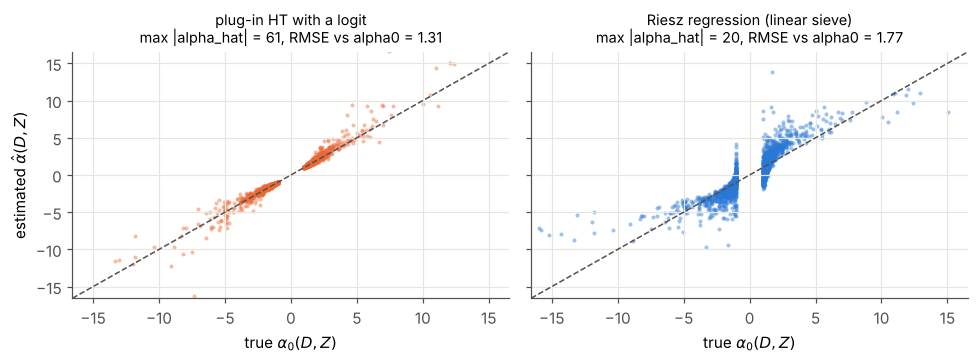

points outside the plotted window: plug-in 0.9%, Riesz 0.1%;  max |alpha0| in this sample = 45


In [9]:
a_plug, a_rr = np.zeros(len(D)), np.zeros(len(D))
for tr, te in KFold(5, shuffle=True, random_state=0).split(Z):
    p_hat = LogisticRegression(C=1e6, max_iter=5000).fit(B[tr][:, 1:], D[tr]).predict_proba(B[te][:, 1:])[:, 1]
    a_plug[te] = ht(D[te], p_hat)                        # correctly specified logit, then invert
    r1, r0 = riesz_linear(B[tr], D[tr], lam=1e-3)
    a_rr[te] = np.where(D[te] == 1, B[te] @ r1, B[te] @ r0)
a_true = ht(D, ps)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True, sharey=True)
lim = np.quantile(np.abs(a_true), 0.995) * 1.1
for ax, a, name, c in [(axes[0], a_plug, "plug-in HT with a logit", ORANGE), (axes[1], a_rr, "Riesz regression (linear sieve)", BLUE)]:
    ax.scatter(a_true, a, s=7, alpha=0.45, color=c, linewidths=0)
    ax.plot([-lim, lim], [-lim, lim], color=INK2, lw=1, ls="--")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(f"{name}\nmax |alpha_hat| = {np.abs(a).max():.0f}, RMSE vs alpha0 = {np.sqrt(np.mean((a-a_true)**2)):.2f}", fontsize=9.5)
    ax.set_xlabel(r"true $\alpha_0(D,Z)$")
axes[0].set_ylabel(r"estimated $\hat\alpha(D,Z)$")
plt.tight_layout(); plt.show()
print(f"points outside the plotted window: plug-in {np.mean(np.abs(a_plug) > lim):.1%}, Riesz {np.mean(np.abs(a_rr) > lim):.1%};  max |alpha0| in this sample = {np.abs(a_true).max():.0f}")

**Read the plot honestly.** Point by point, the correctly specified logit is often *closer* to $\alpha_0$ (smaller RMSE); after all, it is a correct parametric model. Its problem is the tails. Wherever $\hat\varrho$ is near 0 or 1 it reproduces, and out of sample can overshoot, the extreme values of $1/\varrho_0$. Riesz regression finds the best mean-square approximation of $\alpha_0$ *within its dictionary*. A linear sieve cannot represent the sharp tails of $1/\varrho_0$, so its RMSE is larger, but its weights stay bounded.

Which matters for $\hat\theta$? Two facts:
1. The variance of the DML estimator is driven by $E[\hat\alpha^2(Y-\hat\gamma)^2]$, so a handful of huge weights inflate it.
2. The approximation error $\hat\alpha-\alpha_0$ does **not** create first-order bias, because by double robustness it enters only multiplied by $\hat\gamma-\gamma_0$.

Block 4 shows that the trade pays off.

### 3f. Riesz regression with a neural network (slides 40–41, the code from the slides)

In [10]:
if HAS_TORCH:
    class RieszNet(nn.Module):                       # slide 40, unchanged
        def __init__(self, p):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(p + 1, 64), nn.ReLU(), nn.Dropout(0.10),
                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.10),
                nn.Linear(32, 1))
        def forward(self, d, z):
            return self.net(torch.cat([d[:, None], z], dim=1)).squeeze(-1)
        def loss(self, d, z):                        # ATE loading: 0.5*E[a^2] - E[a(1,Z) - a(0,Z)]
            a = self(d, z); a1 = self(torch.ones_like(d), z); a0 = self(torch.zeros_like(d), z)
            return 0.5 * (a ** 2).mean() - (a1 - a0).mean()

    def train_riesz(d_tr, z_tr, d_va, z_va, patience=20):   # slide 41, unchanged except max epochs
        model = RieszNet(z_tr.shape[1])
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
        loader = DataLoader(TensorDataset(d_tr, z_tr), batch_size=512, shuffle=True)
        best, stale, best_state = float("inf"), 0, None
        for _ in range(500):
            model.train()
            for d, z in loader:
                opt.zero_grad(); loss = model.loss(d, z); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                val = model.loss(d_va, z_va).item()          # validation loss only for early stopping
            if val < best - 1e-5:
                best, stale = val, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
                if stale >= patience:
                    break
        model.load_state_dict(best_state)
        return model

    T = lambda x: torch.tensor(x, dtype=torch.float32)
    def riesz_nn_fit_predict(D_tr, Z_tr, D_te, Z_te, seed=0):
        torch.manual_seed(seed)
        idx = np.random.default_rng(seed).permutation(len(D_tr)); va, tr = idx[: len(idx) // 5], idx[len(idx) // 5:]
        model = train_riesz(T(D_tr[tr]), T(Z_tr[tr]), T(D_tr[va]), T(Z_tr[va]))
        model.eval()
        with torch.no_grad():
            return model(T(D_te), T(Z_te)).numpy()

    t0 = time.time()
    a_nn = np.zeros(len(D))
    for k, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=0).split(Z)):   # out of fold, like above
        a_nn[te] = riesz_nn_fit_predict(D[tr], Z[tr], D[te], Z[te], seed=k)
    print(f"5 networks trained in {time.time()-t0:.1f}s   (all weights out of fold)")
    for name, a in [("plug-in HT", a_plug), ("Riesz linear", a_rr), ("RieszNet", a_nn)]:
        print(f"{name:<13} corr with alpha0 = {np.corrcoef(a, a_true)[0,1]:.3f}   RMSE = {np.sqrt(np.mean((a-a_true)**2)):6.2f}   max|alpha| = {np.abs(a).max():6.1f}")

5 networks trained in 6.3s   (all weights out of fold)
plug-in HT    corr with alpha0 = 0.951   RMSE =   1.31   max|alpha| =   60.7
Riesz linear  corr with alpha0 = 0.813   RMSE =   1.77   max|alpha| =   20.2
RieszNet      corr with alpha0 = 0.745   RMSE =   1.98   max|alpha| =    6.8


The network never sees $\varrho_0$, a propensity score, or the formula $1/\varrho$. It only sees the loss built from $m$. Its regularization (dropout, weight decay, early stopping on a validation fold) usually keeps the weights moderate, but nothing *bounds* them: a network can extrapolate to large values in sparse regions of $Z$. Slide 39 lists LASSO and random-forest versions of the same idea.

## 4. Automatic DML (slides 42–48) · 10 min

**Algorithm (slide 42).** Split into $K$ folds. On the data outside fold $k$, fit $\hat\gamma_{-k}$ and $\hat\alpha_{-k}$. For $i$ in fold $k$:
$$\hat\psi_i = \hat\gamma_{-k}(1,Z_i)-\hat\gamma_{-k}(0,Z_i) + \hat\alpha_{-k}(D_i,Z_i)\{Y_i-\hat\gamma_{-k}(D_i,Z_i)\},\qquad \hat\theta = \tfrac1n\textstyle\sum_i\hat\psi_i,\qquad \widehat{se} = \tfrac1n\sqrt{\textstyle\sum_i(\hat\psi_i-\hat\theta)^2}.$$
(The last expression equals $\hat\sigma_\psi/\sqrt n$.) Outcome regressions: ridge by arm on the dictionary $\varphi$. Note that $\varphi$ does **not** contain $\sin(2Z_2)$, so $\hat\gamma$ is deliberately imperfect and the correction term has real work to do.

In [11]:
def auto_dml_ate(Y, D, Z, alpha_method, K=5, seed=0):
    n = len(Y); B = phi(Z); psi = np.zeros(n); amax = 0.0
    for tr, te in KFold(K, shuffle=True, random_state=seed).split(Z):
        b1 = ridge_arm(B[tr][D[tr] == 1], Y[tr][D[tr] == 1]); b0 = ridge_arm(B[tr][D[tr] == 0], Y[tr][D[tr] == 0])
        g1, g0 = B[te] @ b1, B[te] @ b0
        if alpha_method == "none":                       # plug-in only: E_n[g(1,Z) - g(0,Z)]
            a = np.zeros(len(te))
        elif alpha_method == "plug-in HT":
            p = LogisticRegression(C=1e6, max_iter=5000).fit(B[tr][:, 1:], D[tr]).predict_proba(B[te][:, 1:])[:, 1]
            a = ht(D[te], p)
        elif alpha_method == "Riesz linear":
            r1, r0 = riesz_linear(B[tr], D[tr]); a = np.where(D[te] == 1, B[te] @ r1, B[te] @ r0)
        elif alpha_method == "RieszNet":
            a = riesz_nn_fit_predict(D[tr], Z[tr], D[te], Z[te], seed=seed)
        psi[te] = g1 - g0 + a * (Y[te] - np.where(D[te] == 1, g1, g0))
        amax = max(amax, np.abs(a).max())
    theta = psi.mean()
    return theta, np.sqrt(np.sum((psi - theta) ** 2)) / n, amax

R_ad = 200
t0 = time.time()
rows = []
for kappa in [0.5, 1.5]:
    res = {m: [] for m in ["none", "plug-in HT", "Riesz linear"]}
    for r in range(R_ad):
        Y, D, Z, _ = dgp_ate(2000, kappa=kappa, seed=r)
        for m in res:
            res[m].append(auto_dml_ate(Y, D, Z, m, seed=r))
    for m, v in res.items():
        v = np.array(v); err = v[:, 0] - 1
        rows.append({"overlap": "good (kappa=0.5)" if kappa == 0.5 else "weak (kappa=1.5)",
                     "alpha": "none (plug-in only)" if m == "none" else m,
                     "bias": err.mean(), "sd": err.std(), "median |error|": np.median(np.abs(err)),
                     "mean se": v[:, 1].mean(), "coverage 95%": np.mean(np.abs(err) / v[:, 1] < 1.96),
                     "median max|alpha|": np.median(v[:, 2])})
print(f"{R_ad} reps x 2 designs in {time.time()-t0:.0f}s (n = 2000, truth = 1)")
pd.DataFrame(rows).set_index(["overlap", "alpha"]).round(3)

200 reps x 2 designs in 10s (n = 2000, truth = 1)


bias     sd  median |error|  mean se  \
overlap          alpha                                                        
good (kappa=0.5) none (plug-in only) -0.003  0.058           0.040    0.014   
                 plug-in HT           0.002  0.060           0.046    0.062   
                 Riesz linear        -0.001  0.060           0.042    0.060   
weak (kappa=1.5) none (plug-in only) -0.028  0.078           0.055    0.016   
                 plug-in HT           0.013  0.182           0.080    0.139   
                 Riesz linear        -0.024  0.077           0.051    0.078   

                                      coverage 95%  median max|alpha|  
overlap          alpha                                                 
good (kappa=0.5) none (plug-in only)         0.355              0.000  
                 plug-in HT                  0.945             12.476  
                 Riesz linear                0.960              6.112  
weak (kappa=1.5) none (plug-in only)         0.275              0.000  
                 plug-in HT                  0.955             77.228  
                 Riesz linear                0.940             13.913

**Read the table.**
* **No correction.** The plug-in's spread is fine, but its "standard error" ignores the estimation of $\gamma$ and coverage collapses. There is no valid inference without the orthogonal score.
* **Good overlap.** Plug-in HT and Riesz regression behave the same.
* **Weak overlap.** The plug-in HT weights explode, and with them the standard deviation of $\hat\theta$; its standard error also understates the actual sd. Riesz regression keeps the weights several times smaller and cuts the sd by more than half, with calibrated standard errors. The price is a small bias, the product of the $\alpha$-approximation error and the $\gamma$ error. This is the slide 37 point.

**RieszNet inside Auto-DML (one dataset, weak overlap).** Same function, `alpha_method="RieszNet"` (about 15 s):

In [12]:
if HAS_TORCH:
    Y, D, Z, _ = dgp_ate(2000, kappa=1.5, seed=11)
    t0 = time.time()
    tab = {m: auto_dml_ate(Y, D, Z, m, seed=0) for m in ["plug-in HT", "Riesz linear", "RieszNet"]}
    print(f"({time.time()-t0:.0f}s)   truth = 1")
    for m, (th, se, amax) in tab.items():
        print(f"{m:<13} theta = {th:.3f}  se = {se:.3f}  95% CI [{th-1.96*se:.3f}, {th+1.96*se:.3f}]  max|alpha| = {amax:.1f}")

(12s)   truth = 1
plug-in HT    theta = 0.892  se = 0.088  95% CI [0.719, 1.065]  max|alpha| = 67.2
Riesz linear  theta = 0.888  se = 0.077  95% CI [0.737, 1.040]  max|alpha| = 15.7
RieszNet      theta = 1.048  se = 0.124  95% CI [0.805, 1.291]  max|alpha| = 66.4


One dataset is an anecdote, so judge it by the weights and standard errors, not by which point estimate lands nearest 1. Note that the network's out-of-fold weights are not bounded the way the sieve's are. The RieszNet paper (Chernozhukov et al., 2022b) learns $\gamma$ and $\alpha$ jointly with shared layers, which regularizes both; Assignment 4 asks you for the Monte Carlo comparison.

### 4b. LATE: two ATE-type functionals, one Riesz representer (slides 45–48)

$$\theta_{\text{LATE}} = \frac{E[\mu_0(1,Z)-\mu_0(0,Z)]}{E[\eta_0(1,Z)-\eta_0(0,Z)]},\qquad \mu_0(W,Z) = E[Y|W,Z],\ \ \eta_0(W,Z) = E[D|W,Z].$$
Numerator and denominator are ATE functionals **in the instrument $W$**, so both share the same $\alpha_0(W,Z) = W/\varrho_0(Z) - (1-W)/(1-\varrho_0(Z))$ (slide 46), and one Riesz regression in $(W,Z)$ serves both. The estimator is $\hat\theta = \sum\hat\psi_{Y,i}/\sum\hat\psi_{D,i}$ (slide 47), with the delta-method influence function $(\hat\psi_{Y,i}-\hat\theta\hat\psi_{D,i})/\bar\psi_D$ for the standard error.

Simulation: the instrument (an encouragement) is more likely for high $Z_1$; always-takers are also more common at high $Z_1$ and have higher $Y_0$, so $W$ is **not** randomly assigned unconditionally; compliance and the treatment effect both vary with $Z_3$.

In [13]:
def dgp_late(n, p=20, seed=0):
    r = np.random.default_rng(seed)
    Z = r.standard_normal((n, p))
    W = (r.uniform(size=n) < expit(0.8 * Z[:, 0] - 0.5 * Z[:, 1])).astype(float)
    u = r.uniform(size=n)
    p_c = 0.3 + 0.4 * expit(Z[:, 2])                      # complier share rises with Z3
    p_a = (1 - p_c) * expit(Z[:, 0])                      # always-takers more common when Z1 is high
    typ = np.where(u < p_c, "C", np.where(u < p_c + p_a, "A", "N"))
    D = np.where(typ == "C", W, (typ == "A").astype(float))
    tau = 1 + Z[:, 2] + 0.5 * (typ == "A")                # heterogeneous effects
    Y = Z[:, 0] + 0.5 * Z[:, 1] ** 2 + 0.5 * (typ == "A") + D * tau + r.standard_normal(n)
    return Y, D, W, Z, tau[typ == "C"].mean()

def auto_dml_late(Y, D, W, Z, K=5, seed=0):
    n = len(Y); B = phi(Z); psiY, psiD = np.zeros(n), np.zeros(n)
    for tr, te in KFold(K, shuffle=True, random_state=seed).split(Z):
        r1, r0 = riesz_linear(B[tr], W[tr]); a = np.where(W[te] == 1, B[te] @ r1, B[te] @ r0)  # ONE alpha
        for T_, psi in [(Y, psiY), (D, psiD)]:
            f1 = B[te] @ ridge_arm(B[tr][W[tr] == 1], T_[tr][W[tr] == 1])
            f0 = B[te] @ ridge_arm(B[tr][W[tr] == 0], T_[tr][W[tr] == 0])
            psi[te] = f1 - f0 + a * (T_[te] - np.where(W[te] == 1, f1, f0))
    theta = psiY.sum() / psiD.sum()
    infl = (psiY - theta * psiD) / psiD.mean()
    return theta, np.sqrt(np.sum(infl ** 2)) / n

late_true = dgp_late(2_000_000, seed=123)[4]
Yb, Db, Wb, _, _ = dgp_late(500_000, seed=5)
wald = (Yb[Wb == 1].mean() - Yb[Wb == 0].mean()) / (Db[Wb == 1].mean() - Db[Wb == 0].mean())
t0 = time.time()
res = np.array([auto_dml_late(*dgp_late(3000, seed=r)[:4], seed=r) for r in range(200)])
err = res[:, 0] - late_true
print(f"true LATE (complier average effect) = {late_true:.3f};  unconditional Wald (big sample) = {wald:.3f}")
print(f"Auto-DML LATE over 200 reps ({time.time()-t0:.0f}s): bias {err.mean():+.3f}, sd {err.std():.3f}, mean se {res[:,1].mean():.3f}, coverage {np.mean(np.abs(err)/res[:,1] < 1.96):.2f}")

true LATE (complier average effect) = 1.165;  unconditional Wald (big sample) = 2.415
Auto-DML LATE over 200 reps (2s): bias +0.009, sd 0.100, mean se 0.097, coverage 0.94


The unconditional Wald ratio is badly biased because $W$ is confounded by $Z_1$. Conditioning on $Z$ through the orthogonal score recovers the complier average effect with correct coverage, even though $\alpha$ was learned without writing down the instrument propensity.

## 5. Wrap-up · 2 min

1. **A target is a functional** $\theta_0=E[m(X,\gamma_0)]$. If it is linear and continuous in $\gamma$, it has a **Riesz representer** $\alpha_0$ with $E[m(X,\gamma)]=E[\alpha_0\gamma]$ (slides 28–32). For the ATE it is the Horvitz–Thompson weight; for the ATT it has the odds form.
2. $\alpha_0$ is the **exchange rate** from nuisance errors to target errors. Adding $\alpha_0(Y-\gamma)$ cancels them, so the score is orthogonal and **doubly robust**: error $=-E[(\alpha-\alpha_0)(\gamma-\gamma_0)]$ (slides 33–36).
3. **Riesz regression** learns $\alpha_0$ by minimizing $E[\alpha^2]-2E[m(X,\alpha)]$, which needs only $m$. This makes DML **automatic** and stabilizes the weights under weak overlap; with a linear sieve, it is exact covariate balancing (slides 37–42).
4. LATE reuses one representer for two functionals (slides 45–47).

**Preview, Assignment 4 & slides 49–50.** The DiD group-time ATT is an ATT-type functional of $E[\Delta Y\mid C_{gt},Z]$. Its representer, $-P(G=g\mid Z)C_{gt}/\{\eta_{g,0}P(C_{gt}=1\mid Z)\}$, is the odds form from Block 1a, and the Riesz loss on slide 50 is $\tfrac12E[\alpha^2] + E[\mathbb 1\{G=g\}\alpha(1,Z)/\eta_{g,0}]$, which is our loss with this new $m$. In the assignment you will derive it and use it.

**References.** Chernozhukov, Escanciano, Ichimura & Newey (2022a, *Econometrica*); Chernozhukov, Newey & Singh (2022c, *Econometrica*); Chernozhukov, Newey, Quintas-Martínez & Syrgkanis (2022b, ICML: RieszNet/ForestRiesz; 2024b, arXiv:2104.14737); Robins & Rotnitzky (2001); Rothe & Firpo (2019); Chernozhukov et al. (2024a), *Applied Causal Inference Powered by ML and AI*, Ch. 5, 10, 13.